# 4. The layer zoo

**What you will learn:** what GraphSAGE, GAT, GIN and D-MPNN each change about
the message-passing recipe, what that buys and costs on molecules, and how to
read a GAT's attention weights off a real structure.

Every layer here answers the same three questions differently:

| layer | message | aggregate | update |
|---|---|---|---|
| **GCN** | $W h_j$ | degree-normalised sum | — (self-loop does it) |
| **GraphSAGE** | $h_j$ | **mean** | $W_l(\text{agg}) + W_r h_i$, separate weight for self |
| **GAT** | $W h_j$ | **learned weighted** sum, weights from attention | — (self-loop) |
| **GIN** | $h_j$ | **sum** | $\mathrm{MLP}((1+\epsilon)h_i + \text{agg})$ |
| **D-MPNN** | state on the **bond** $u\!\to\!v$ | sum over bonds into $v$, **excluding the reverse bond** | $\mathrm{ReLU}(h^0 + W_h m)$ |

References, all real and worth reading:

* Hamilton, W.; Ying, Z.; Leskovec, J. "Inductive Representation Learning on
  Large Graphs." NeurIPS 2017. DOI:
  [10.48550/arXiv.1706.02216](https://doi.org/10.48550/arXiv.1706.02216)
* Veličković, P. et al. "Graph Attention Networks." ICLR 2018. DOI:
  [10.48550/arXiv.1710.10903](https://doi.org/10.48550/arXiv.1710.10903)
* Xu, K. et al. "How Powerful are Graph Neural Networks?" ICLR 2019. DOI:
  [10.48550/arXiv.1810.00826](https://doi.org/10.48550/arXiv.1810.00826)
* Yang, K. et al. "Analyzing Learned Molecular Representations for Property
  Prediction." *J. Chem. Inf. Model.* 2019, 59 (8), 3370-3388. DOI:
  [10.1021/acs.jcim.9b00237](https://doi.org/10.1021/acs.jcim.9b00237) — Chemprop.
* Gilmer, J. et al. "Neural Message Passing for Quantum Chemistry." ICML 2017.
  DOI: [10.48550/arXiv.1704.01212](https://doi.org/10.48550/arXiv.1704.01212) —
  the paper that unified all of these under one framework.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from mgnn import features as F
from mgnn.data import WORKED_TASKS, load_tox21_graphs
from mgnn.interpret import aggregate_gat_attention
from mgnn.layers import (
    DMPNNLayer,
    GATLayer,
    GCNLayer,
    GINLayer,
    SAGELayer,
    dmpnn_reference_forward,
)
from mgnn.models import MolecularGNN
from mgnn.splits import scaffold_split
from mgnn.train import evaluate, set_seed, train_model
from mgnn.viz import draw_molecule_with_atom_weights, draw_molecule_with_indices, show

np.set_printoptions(precision=3, suppress=True, linewidth=130)
plt.rcParams["figure.dpi"] = 110
set_seed(0)

smiles = "CC(=O)Nc1ccc(O)cc1"          # paracetamol
graph = F.smiles_to_graph(smiles)
labels = [f"{s}{i}" for i, s in enumerate(graph.atom_symbols())]

## 4.1 Mean or sum? A worked disagreement

GraphSAGE averages its neighbours; GIN sums them. The difference sounds
trivial and is not: **mean throws away how many neighbours there were.**

Consider a carbon with one methyl neighbour and a carbon with three identical
methyl neighbours. To a mean aggregator these are identical. To a sum
aggregator they differ by a factor of three. In chemistry that distinction is
the difference between a terminal and a quaternary centre.

Here is the demonstration, with an artificial molecule pair.

In [2]:
star = F.smiles_to_graph("CC(C)C")        # isobutane: central C has 3 methyls
chain = F.smiles_to_graph("CC")           # ethane: each C has 1 methyl

torch.manual_seed(1)
sage = SAGELayer(F.ATOM_FEATURE_DIM, 4, root_weight=False, bias=False)
mlp = nn.Sequential(nn.Linear(F.ATOM_FEATURE_DIM, 4))
gin = GINLayer(mlp, eps=-1.0)             # eps=-1 removes the self term entirely

print("GraphSAGE (mean) -- central atom of isobutane vs a carbon of ethane:")
print("  isobutane C1:", sage(star.x, star.edge_index)[1].detach().numpy())
print("  ethane    C0:", sage(chain.x, chain.edge_index)[0].detach().numpy())
print("\nGIN (sum) -- same two atoms:")
print("  isobutane C1:", gin(star.x, star.edge_index)[1].detach().numpy())
print("  ethane    C0:", gin(chain.x, chain.edge_index)[0].detach().numpy())
print("\nThe mean aggregator gives the same answer for both; the sum aggregator")
print("sees three neighbours instead of one. Xu et al. built GIN on exactly this")
print("observation -- sum aggregation makes the layer as discriminative as the")
print("1-Weisfeiler-Lehman graph isomorphism test, mean and max are strictly weaker.")

GraphSAGE (mean) -- central atom of isobutane vs a carbon of ethane:
  isobutane C1: [-0.056 -0.192  0.036  0.188]
  ethane    C0: [-0.056 -0.192  0.036  0.188]

GIN (sum) -- same two atoms:
  isobutane C1: [ 0.371  0.33  -0.04   0.654]
  ethane    C0: [0.186 0.019 0.001 0.265]

The mean aggregator gives the same answer for both; the sum aggregator
sees three neighbours instead of one. Xu et al. built GIN on exactly this
observation -- sum aggregation makes the layer as discriminative as the
1-Weisfeiler-Lehman graph isomorphism test, mean and max are strictly weaker.


## 4.2 GraphSAGE: a separate weight for yourself

$$h'_i = W_l \cdot \mathrm{mean}_{j \in N(i)} h_j \;+\; W_r h_i$$

GCN mixes an atom's own features into the neighbourhood through the self-loop,
so "me" and "my neighbours" share one weight matrix. GraphSAGE splits them.
The layer can then learn, for instance, that the centre atom's element matters
more than its environment — useful for atom-level tasks, and harmless for
molecule-level ones.

In [3]:
sage = SAGELayer(F.ATOM_FEATURE_DIM, 16)
print("SAGE out:", tuple(sage(graph.x, graph.edge_index).shape))
print("parameters:", sum(p.numel() for p in sage.parameters()),
      " (two weight matrices, hence about twice a GCN layer)")
gcn = GCNLayer(F.ATOM_FEATURE_DIM, 16)
print("GCN parameters: ", sum(p.numel() for p in gcn.parameters()))

SAGE out: (11, 16)
parameters: 1328  (two weight matrices, hence about twice a GCN layer)
GCN parameters:  672


## 4.3 GAT: let the model decide which neighbours matter

For the directed edge $j \to i$,

$$ e_{ij} = \mathrm{LeakyReLU}\big(a_{src}^\top W h_j + a_{dst}^\top W h_i\big),
   \qquad \alpha_{ij} = \mathrm{softmax}_{j \in N(i) \cup \{i\}} (e_{ij}), $$

$$ h'_i = \sum_j \alpha_{ij} W h_j .$$

Instead of a fixed $1/\sqrt{d_i d_j}$, the weight on each bond is computed from
the two atoms it joins. Multiple heads run in parallel and are concatenated,
so different heads can specialise.

The attention coefficients are the practical reason to care: they are the
easiest thing in a GNN to show a chemist.

In [4]:
gat = GATLayer(F.ATOM_FEATURE_DIM, 8, heads=4)
out, (ei, alpha) = gat(graph.x, graph.edge_index, return_attention=True)
print("out:", tuple(out.shape), " (8 features x 4 heads concatenated)")
print("alpha:", tuple(alpha.shape),
      f" ({graph.num_edges} bonds + {graph.num_nodes} self-loops, 4 heads)")

# every atom's incoming attention is a probability distribution
from mgnn.layers import scatter_sum  # noqa: E402
received = scatter_sum(alpha, ei[1], graph.num_nodes)
print("\nincoming attention per atom sums to 1:",
      bool(torch.allclose(received, torch.ones_like(received), atol=1e-5)))

out: (11, 32)  (8 features x 4 heads concatenated)
alpha: (33, 4)  (22 bonds + 11 self-loops, 4 heads)

incoming attention per atom sums to 1: True


### Attention on an untrained layer means nothing

This is worth stating plainly, because published figures often skip it: the
attention weights of a randomly initialised layer are an artefact of the
initialisation. To get weights worth drawing we train a small GAT model on
Tox21 first (a few epochs, a few seconds), then read the attention off.

In [5]:
ds = load_tox21_graphs(tasks=WORKED_TASKS, verbose=False)
train_idx, valid_idx, test_idx = scaffold_split(ds.smiles, 0.8, 0.1, 0.1)
d_train, d_valid = ds.subset(train_idx[:2500]), ds.subset(valid_idx)
print(f"training a small GAT on {len(d_train)} molecules "
      f"(a subset, to keep this notebook quick)")

set_seed(0)
gat_model = MolecularGNN(n_tasks=2, hidden_dim=64, n_layers=3, layer_kind="gat",
                         heads=4, pooling="sum", dropout=0.1)
history = train_model(gat_model, d_train.graphs, d_valid.graphs, WORKED_TASKS,
                      epochs=8, batch_size=64, lr=1e-3,
                      pos_weight=torch.tensor([5.0, 3.0]),
                      verbose=True, early_stopping_patience=None)

training a small GAT on 2500 molecules (a subset, to keep this notebook quick)


epoch   1 | train loss 0.7587 | valid ROC-AUC 0.682 | valid PR-AUC 0.268


epoch   2 | train loss 0.6509 | valid ROC-AUC 0.666 | valid PR-AUC 0.329


epoch   3 | train loss 0.6138 | valid ROC-AUC 0.684 | valid PR-AUC 0.395


epoch   4 | train loss 0.6056 | valid ROC-AUC 0.714 | valid PR-AUC 0.422


epoch   5 | train loss 0.5746 | valid ROC-AUC 0.671 | valid PR-AUC 0.395


epoch   6 | train loss 0.5799 | valid ROC-AUC 0.735 | valid PR-AUC 0.467


epoch   7 | train loss 0.5704 | valid ROC-AUC 0.711 | valid PR-AUC 0.420


epoch   8 | train loss 0.5199 | valid ROC-AUC 0.699 | valid PR-AUC 0.407


,degree,mean attention received
atom,,
C0,1,0.500
C1,3,0.250
O2,1,0.500
N3,2,0.333
C4,3,0.250
C5,2,0.333
C6,2,0.333
C7,3,0.250
O8,1,0.500


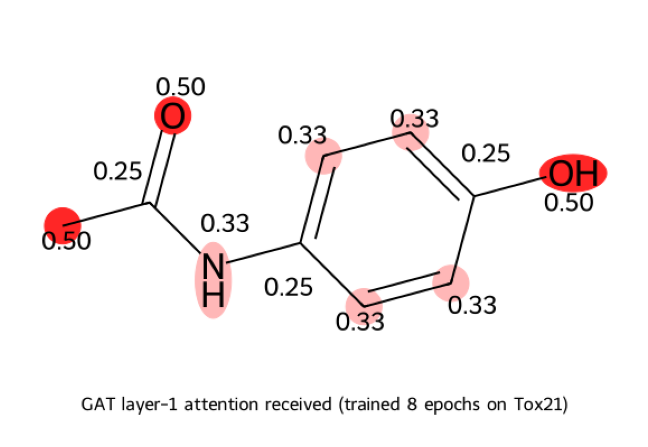

In [6]:
trained_layer = gat_model.convs[0]
h0 = gat_model.embed(graph.x)
per_atom, per_edge = aggregate_gat_attention(trained_layer, h0, graph.edge_index)

att = pd.DataFrame({"atom": labels, "degree": F.degree_vector(F.adjacency_matrix(graph)).astype(int),
                    "mean attention received": per_atom}).set_index("atom")
display(att.style.format({"mean attention received": "{:.3f}"})
        .background_gradient(cmap="Reds", subset=["mean attention received"]))

show(draw_molecule_with_atom_weights(
    smiles, per_atom, diverging=False, annotate_values=True, size=(560, 380),
    legend="GAT layer-1 attention received (trained 8 epochs on Tox21)"))
plt.show()

Read this figure carefully and sceptically. Attention tells you where the
layer *looked*, not what changed the prediction — a low-degree atom
automatically receives high attention per edge simply because its softmax has
few competitors. Compare the attention column with the degree column above
before reading chemistry into it. Notebook 08 puts attention next to gradient
attribution, which answers the causal question instead.

## 4.4 GIN: sum, then an MLP

$$h'_i = \mathrm{MLP}\big((1 + \epsilon)\,h_i + \textstyle\sum_{j \in N(i)} h_j\big)$$

No normalisation, no attention — sum aggregation and a two-layer MLP, which is
enough to make the layer injective over multisets of neighbours (that is the
theorem in Xu et al.). On molecular benchmarks GIN is a consistently strong
and cheap baseline, and it is the layer notebook 07 uses.

In [7]:
gin = GINLayer(nn.Sequential(nn.Linear(F.ATOM_FEATURE_DIM, 32), nn.ReLU(),
                             nn.Linear(32, 16)), eps=0.0, train_eps=True)
print("GIN out:", tuple(gin(graph.x, graph.edge_index).shape))
print("trainable eps:", float(gin.eps))
print("parameters:", sum(p.numel() for p in gin.parameters()),
      " (the MLP dominates)")

GIN out: (11, 16)
trainable eps: 0.0
parameters: 1873  (the MLP dominates)


## 4.5 D-MPNN: put the state on the bond, not the atom

Chemprop's layer keeps a hidden state for each **directed bond** $v \to w$, and
updates it from the bonds flowing into $v$ **excluding the reverse bond**
$w \to v$:

$$ m_{vw} = \sum_{u \in N(v) \setminus \{w\}} h_{uv}, \qquad
   h_{vw} \leftarrow \mathrm{ReLU}(h^0_{vw} + W_h m_{vw}) $$

Why exclude it? In an atom-centred network, a feature sent from atom A to atom
B comes straight back to A at the next step. Part of what a two-layer model
"learns about the neighbourhood" is therefore an echo of itself. Excluding the
reverse bond removes the echo, and it also lets the layer use **bond
features** — bond order, conjugation, ring membership — which GCN and GIN
cannot see at all.

Let us verify the echo is really gone.

In [8]:
layer = DMPNNLayer(F.ATOM_FEATURE_DIM, F.BOND_FEATURE_DIM, 16, depth=3)
out = layer(graph.x, graph.edge_index, graph.edge_attr)
print("D-MPNN out:", tuple(out.shape), " (one vector per atom, as usual)")

rev = DMPNNLayer.reverse_edge_index(graph.edge_index)
print("\nevery bond found its reverse partner:", bool((rev >= 0).all()))
print("the mapping is its own inverse:", bool(torch.equal(rev[rev], torch.arange(graph.num_edges))))

k = 0
v, w = int(graph.edge_index[0, k]), int(graph.edge_index[1, k])
print(f"\nbond {k} is {labels[v]} -> {labels[w]}; its reverse is bond {int(rev[k])} "
      f"({labels[int(graph.edge_index[0, rev[k]])]} -> {labels[int(graph.edge_index[1, rev[k]])]})")

D-MPNN out: (11, 16)  (one vector per atom, as usual)

every bond found its reverse partner: True
the mapping is its own inverse: True

bond 0 is C0 -> C1; its reverse is bond 1 (C1 -> C0)


And a correctness check of a different kind: the vectorised implementation is
compared against a deliberately naive loop-based one written straight from the
equations. There is no PyTorch Geometric layer to compare D-MPNN against, so
this independent reference *is* the test (`tests/test_dmpnn.py` runs it on
every test molecule and at four depths).

In [9]:
fast = layer(graph.x, graph.edge_index, graph.edge_attr)
slow = dmpnn_reference_forward(layer, graph.x, graph.edge_index, graph.edge_attr)
print("vectorised vs loop reference, max difference:",
      float((fast - slow).abs().max()))

vectorised vs loop reference, max difference: 2.384185791015625e-07


## 4.6 All four against PyTorch Geometric

For the three layers that have a PyG counterpart, copy the parameters across
and compare. This is the table that justifies trusting everything else in the
repository.

In [10]:
from torch_geometric.nn import GATConv, GCNConv, GINConv, SAGEConv  # noqa: E402

rows = []
for smi in ["CCO", "c1ccccc1", "CC(=O)Nc1ccc(O)cc1", "C[N+](C)(C)C",
            "CC(=O)[O-].[Na+]", "[Na+]"]:
    g = F.smiles_to_graph(smi)
    d = F.ATOM_FEATURE_DIM

    p = GCNConv(d, 8); m = GCNLayer(d, 8).copy_weights_from_pyg(p)
    gcn_diff = float((p(g.x, g.edge_index) - m(g.x, g.edge_index)).abs().max())

    p = SAGEConv(d, 8); m = SAGELayer(d, 8).copy_weights_from_pyg(p)
    sage_diff = float((p(g.x, g.edge_index) - m(g.x, g.edge_index)).abs().max())

    p = GATConv(d, 8, heads=4); m = GATLayer(d, 8, heads=4).copy_weights_from_pyg(p)
    gat_diff = float((p(g.x, g.edge_index) - m(g.x, g.edge_index)).abs().max())

    shared = nn.Sequential(nn.Linear(d, 12), nn.ReLU(), nn.Linear(12, 8))
    p = GINConv(shared, eps=0.0); m = GINLayer(shared, eps=0.0)
    gin_diff = float((p(g.x, g.edge_index) - m(g.x, g.edge_index)).abs().max())

    rows.append({"molecule": smi, "GCN": gcn_diff, "GraphSAGE": sage_diff,
                 "GAT": gat_diff, "GIN": gin_diff})

display(pd.DataFrame(rows).set_index("molecule").style.format("{:.2e}"))
print("All differences are at float32 rounding level: the hand-written layers")
print("are the same arithmetic, not an approximation.")

,GCN,GraphSAGE,GAT,GIN
molecule,,,,
CCO,5.96e-08,0.00e+00,0.00e+00,0.00e+00
c1ccccc1,5.96e-08,0.00e+00,0.00e+00,0.00e+00
CC(=O)Nc1ccc(O)cc1,1.19e-07,0.00e+00,0.00e+00,0.00e+00
C[N+](C)(C)C,5.96e-08,0.00e+00,0.00e+00,0.00e+00
CC(=O)[O-].[Na+],5.96e-08,0.00e+00,0.00e+00,0.00e+00
[Na+],0.00e+00,0.00e+00,0.00e+00,0.00e+00


All differences are at float32 rounding level: the hand-written layers
are the same arithmetic, not an approximation.


## 4.7 What each layer can and cannot see

A summary table to keep. The "sees bond features" column is the one most often
forgotten, and it is the reason D-MPNN tends to win on small chemical data sets.

In [11]:
summary = pd.DataFrame([
    {"layer": "GCN", "aggregation": "degree-normalised sum", "sees bond features": "no",
     "sees degree": "partly (via normalisation)", "learned edge weights": "no",
     "params per layer (64->64)": sum(p.numel() for p in GCNLayer(64, 64).parameters())},
    {"layer": "GraphSAGE", "aggregation": "mean + separate self weight", "sees bond features": "no",
     "sees degree": "no", "learned edge weights": "no",
     "params per layer (64->64)": sum(p.numel() for p in SAGELayer(64, 64).parameters())},
    {"layer": "GAT (4 heads)", "aggregation": "attention-weighted sum", "sees bond features": "no",
     "sees degree": "indirectly", "learned edge weights": "yes",
     "params per layer (64->64)": sum(p.numel() for p in GATLayer(64, 16, heads=4).parameters())},
    {"layer": "GIN", "aggregation": "sum", "sees bond features": "no",
     "sees degree": "yes (sum keeps the count)", "learned edge weights": "no",
     "params per layer (64->64)": sum(p.numel() for p in GINLayer(
         nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 64))).parameters())},
    {"layer": "D-MPNN", "aggregation": "sum over bonds, reverse excluded", "sees bond features": "yes",
     "sees degree": "yes", "learned edge weights": "no",
     "params per layer (64->64)": sum(p.numel() for p in DMPNNLayer(64, 12, 64).parameters())},
]).set_index("layer")
display(summary)

,aggregation,sees bond features,sees degree,learned edge weights,params per layer (64->64)
layer,,,,,
GCN,degree-normalised sum,no,partly (via normalisation),no,4160
GraphSAGE,mean + separate self weight,no,no,no,8256
GAT (4 heads),attention-weighted sum,no,indirectly,yes,4288
GIN,sum,no,yes (sum keeps the count),no,8320
D-MPNN,"sum over bonds, reverse excluded",yes,yes,no,17216


## 4.8 A quick empirical comparison

Five architectures, same budget, same scaffold split, eight epochs on a 2,500
molecule subset. **These numbers are a smoke test, not a benchmark**: one seed,
a truncated training set, far too few epochs. They are here to show the
machinery runs and to give a feel for the spread, not to rank the layers.
Notebook 07 trains properly on the full set.

In [12]:
rows = []
for kind in ["gcn", "sage", "gat", "gin", "dmpnn"]:
    set_seed(0)
    model = MolecularGNN(n_tasks=2, hidden_dim=64, n_layers=3, layer_kind=kind,
                         heads=4, pooling="sum", dropout=0.1)
    train_model(model, d_train.graphs, d_valid.graphs, WORKED_TASKS, epochs=8,
                batch_size=64, lr=1e-3, pos_weight=torch.tensor([5.0, 3.0]),
                verbose=False, early_stopping_patience=None)
    m = evaluate(model, d_valid.graphs, WORKED_TASKS)
    rows.append({"layer": kind, "parameters": model.n_parameters(),
                 "valid ROC-AUC (mean)": m["mean_roc_auc"],
                 "NR-AR": m["per_task"]["NR-AR"]["roc_auc"],
                 "SR-MMP": m["per_task"]["SR-MMP"]["roc_auc"]})
    print(f"  {kind:<6s} done")

display(pd.DataFrame(rows).set_index("layer").style.format({
    "valid ROC-AUC (mean)": "{:.3f}", "NR-AR": "{:.3f}", "SR-MMP": "{:.3f}"}))

  gcn    done


  sage   done


  gat    done


  gin    done


  dmpnn  done


,parameters,valid ROC-AUC (mean),NR-AR,SR-MMP
layer,,,,
gcn,19842,0.726,0.681,0.771
sage,32130,0.725,0.694,0.756
gat,20226,0.732,0.719,0.745
gin,32325,0.738,0.714,0.761
dmpnn,18562,0.739,0.702,0.777


## What to take away

* **Sum** keeps neighbour counts, **mean** discards them. On molecules, counts
  are chemistry.
* **GraphSAGE** separates self from neighbourhood; **GAT** learns per-bond
  weights and hands you something interpretable; **GIN** is the strong, cheap
  default; **D-MPNN** is the only one here that can see bond features.
* Attention from an untrained layer is noise. Train first, then look.
* Our implementations agree with PyTorch Geometric to float precision.

**Next:** notebook 05, readout — how a bag of atom vectors becomes one
molecular prediction, and why sum beats mean for molecular size.